In [1]:
from sklearn.datasets import load_breast_cancer

# Load scikit-learn's bundled copy of the UCI dataset.
dataset = load_breast_cancer(as_frame=True)

X = dataset.data.copy()

# Encode malignant as 1 so recall measures detection of malignant cases.
y = (dataset.target == 0).astype(int)
y.name = "target"

df = X.copy()
df["target"] = y

print("Records:", len(df))
print("Input features:", X.shape[1])
print("Missing values:", df.isna().sum().sum())
print("\nClass counts (0 = benign, 1 = malignant):")
print(df["target"].value_counts().sort_index())

df.head()

Records: 569
Input features: 30
Missing values: 0

Class counts (0 = benign, 1 = malignant):
target
0    357
1    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Save original feature values and labels for uploading to Streamlit.
test_data = X_test.copy()
test_data["target"] = y_test
test_data.to_csv("test_data.csv", index=False)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("\nTest class counts (0 = benign, 1 = malignant):")
print(y_test.value_counts().sort_index())
print("\nSaved: test_data.csv")

Training data: (455, 30)
Test data: (114, 30)

Test class counts (0 = benign, 1 = malignant):
target
0    72
1    42
Name: count, dtype: int64

Saved: test_data.csv


In [3]:
from pathlib import Path
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Scaling is fitted only on training data when the pipeline is fitted.
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=3,
            random_state=42
        ))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Naive Bayes": Pipeline([
        ("classifier", GaussianNB())
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=42
        ))
    ])
}

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

Path("model").mkdir(exist_ok=True)

for name, model in models.items():
    model.fit(X_train, y_train)
    joblib.dump(model, Path("model") / model_files[name])
    print(f"Trained and saved: {name}")

Trained and saved: Logistic Regression
Trained and saved: Decision Tree
Trained and saved: KNN
Trained and saved: Naive Bayes
Trained and saved: Support Vector Machine


/Users/ziddi/Desktop/Learning/MTech/01-MachineLearning/Assignments/Assignment2/2026ak05270-ml/.venv312/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [4]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    # Probability of malignant class (target = 1).
    positive_index = list(model.classes_).index(1)
    y_probability = model.predict_proba(X_test)[:, positive_index]

    results.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_probability),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

# Preserve full precision in the saved results.
results_df.to_csv("model_comparison.csv", index=False)

# Round only for display.
results_df.round(4)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9035,0.9471,0.9429,0.7857,0.8571,0.7926
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


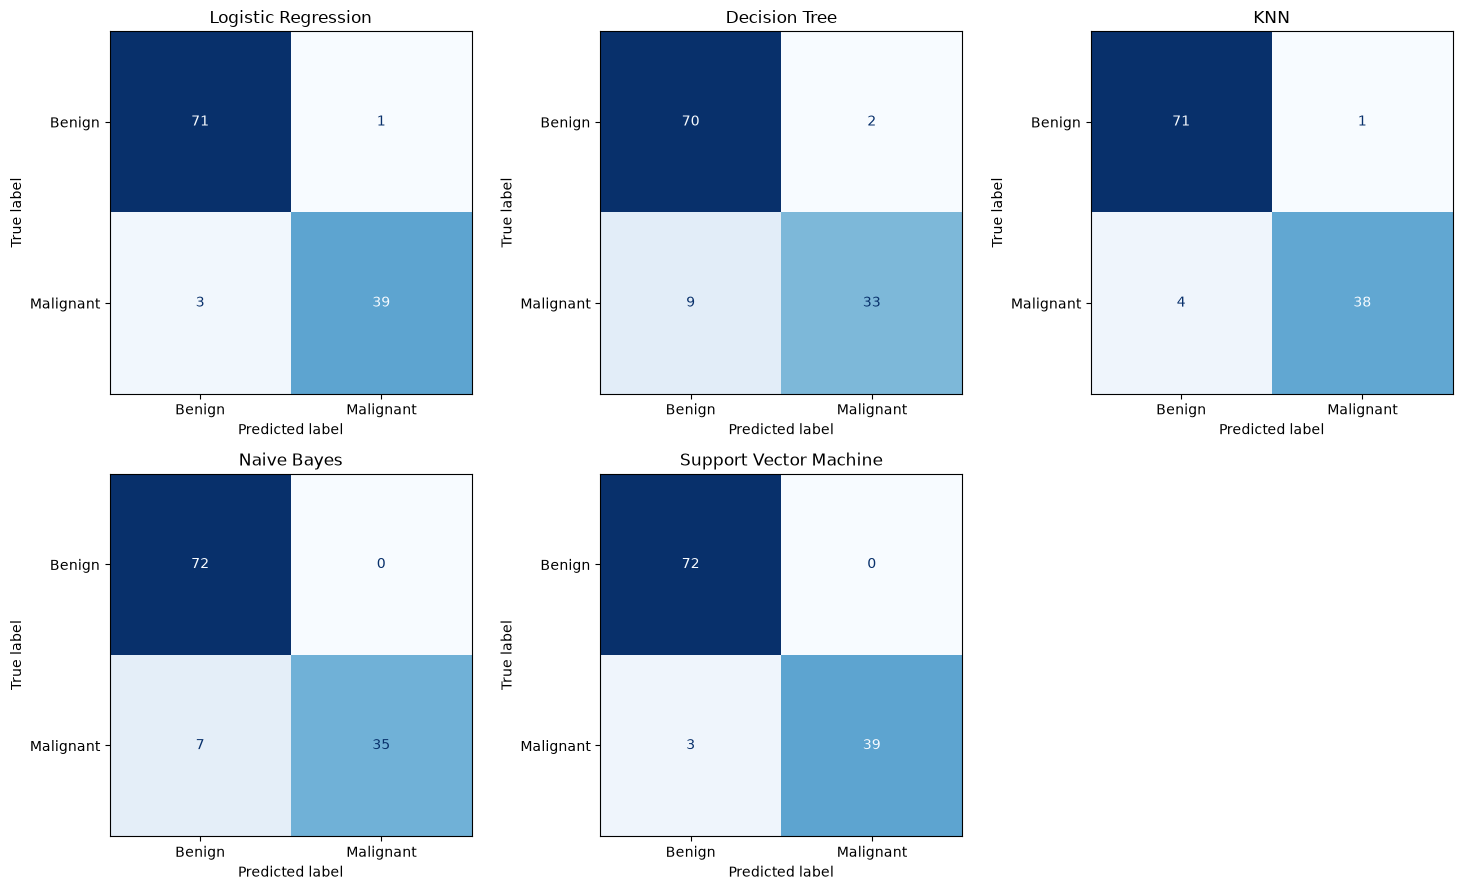

All five saved models reproduce the original predictions.


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, (name, model) in zip(axes, models.items()):
    # Reload the saved pipeline, just as the Streamlit app will.
    saved_model = joblib.load(Path("model") / model_files[name])
    saved_predictions = saved_model.predict(X_test)

    if not np.array_equal(saved_predictions, model.predict(X_test)):
        raise ValueError(f"Saved-model predictions differ: {name}")

    cm = confusion_matrix(y_test, saved_predictions, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

axes[-1].axis("off")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

print("All five saved models reproduce the original predictions.")

In [6]:
from importlib.metadata import version
from pathlib import Path

packages = [
    "streamlit", "scikit-learn", "scipy",
    "numpy", "pandas", "matplotlib", "seaborn", "joblib"
]

requirements = "\n".join(
    f"{package}=={version(package)}" for package in packages
) + "\n"

Path("requirements.txt").write_text(requirements)
print(requirements)

streamlit==1.67.0
scikit-learn==1.9.1
scipy==1.18.1
numpy==2.5.4
pandas==3.1.1
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0

